In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import time
import json
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, accuracy_score

In [2]:
BASE_DIR = r"E:\SmartVision-AI\data"
CLASSIFICATION_DIR = os.path.join(BASE_DIR, "classification_v3")

TRAIN_DIR = os.path.join(CLASSIFICATION_DIR, "train")
VAL_DIR = os.path.join(CLASSIFICATION_DIR, "val")
TEST_DIR = os.path.join(CLASSIFICATION_DIR, "test")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
print(torch.cuda.get_device_name(0))

Using device: cuda
NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [4]:
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=val_test_transforms)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=val_test_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

class_names = train_dataset.classes
num_classes = len(class_names)

print("Classes:", num_classes)

Classes: 26


In [5]:
model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(num_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, num_classes)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print(model.fc)

Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=26, bias=True)
)


In [9]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    best_val_acc = 0.0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        print(f"\nEpoch {epoch+1}/{epochs}")
        print("-" * 30)

        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            _, preds = torch.max(outputs, 1)

            train_loss += loss.item() * images.size(0)
            train_correct += torch.sum(preds == labels).item()
            train_total += labels.size(0)

        train_epoch_loss = train_loss / train_total
        train_epoch_acc = train_correct / train_total

        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                _, preds = torch.max(outputs, 1)

                val_loss += loss.item() * images.size(0)
                val_correct += torch.sum(preds == labels).item()
                val_total += labels.size(0)

        val_epoch_loss = val_loss / val_total
        val_epoch_acc = val_correct / val_total

        history["train_loss"].append(train_epoch_loss)
        history["train_acc"].append(train_epoch_acc)
        history["val_loss"].append(val_epoch_loss)
        history["val_acc"].append(val_epoch_acc)

        print(f"Train Loss: {train_epoch_loss:.4f} | Train Acc: {train_epoch_acc:.4f}")
        print(f"Val Loss:   {val_epoch_loss:.4f} | Val Acc:   {val_epoch_acc:.4f}")

        if val_epoch_acc > best_val_acc:

            best_val_acc = val_epoch_acc

            torch.save(
                model.state_dict(),
                r"E:\SmartVision-AI\models\resnet50_best.pth"
            )

            print("✅ Best model saved")

    return history

In [10]:
start_time = time.time()

history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

end_time = time.time()
training_time = end_time - start_time

print(f"Training Time: {training_time/60:.2f} minutes")


Epoch 1/10
------------------------------
Train Loss: 2.1933 | Train Acc: 0.4180
Val Loss:   1.4137 | Val Acc:   0.6084
✅ Best model saved

Epoch 2/10
------------------------------
Train Loss: 1.1591 | Train Acc: 0.6721
Val Loss:   1.0949 | Val Acc:   0.7258
✅ Best model saved

Epoch 3/10
------------------------------
Train Loss: 0.8301 | Train Acc: 0.7685
Val Loss:   0.9927 | Val Acc:   0.7206

Epoch 4/10
------------------------------
Train Loss: 0.6483 | Train Acc: 0.8017
Val Loss:   0.8973 | Val Acc:   0.7415
✅ Best model saved

Epoch 5/10
------------------------------
Train Loss: 0.5159 | Train Acc: 0.8552
Val Loss:   0.9405 | Val Acc:   0.7206

Epoch 6/10
------------------------------
Train Loss: 0.4600 | Train Acc: 0.8631
Val Loss:   0.9098 | Val Acc:   0.7493
✅ Best model saved

Epoch 7/10
------------------------------
Train Loss: 0.4139 | Train Acc: 0.8817
Val Loss:   0.8706 | Val Acc:   0.7781
✅ Best model saved

Epoch 8/10
------------------------------
Train Loss: 0.3

In [11]:
for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

history_finetune = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=5
)


Epoch 1/5
------------------------------
Train Loss: 0.2298 | Train Acc: 0.9273
Val Loss:   0.9495 | Val Acc:   0.7885
✅ Best model saved

Epoch 2/5
------------------------------
Train Loss: 0.1599 | Train Acc: 0.9510
Val Loss:   0.9587 | Val Acc:   0.7833

Epoch 3/5
------------------------------
Train Loss: 0.1016 | Train Acc: 0.9679
Val Loss:   1.0391 | Val Acc:   0.7859

Epoch 4/5
------------------------------
Train Loss: 0.1145 | Train Acc: 0.9651
Val Loss:   0.9880 | Val Acc:   0.8042
✅ Best model saved

Epoch 5/5
------------------------------
Train Loss: 0.0861 | Train Acc: 0.9763
Val Loss:   1.0488 | Val Acc:   0.7807


In [12]:
model.load_state_dict(torch.load(r"E:\SmartVision-AI\models\resnet50_best.pth"))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("ResNet50 Test Accuracy:", round(test_acc, 4))
print()
print(classification_report(all_labels, all_preds, target_names=class_names))

ResNet50 Test Accuracy: 0.8184

               precision    recall  f1-score   support

     airplane       0.69      0.92      0.79        12
          bed       0.60      0.69      0.64        13
        bench       0.71      0.67      0.69        15
      bicycle       0.88      1.00      0.94        15
         bird       1.00      0.80      0.89        15
       bottle       1.00      0.86      0.92        14
         bowl       0.53      0.62      0.57        13
          bus       1.00      0.87      0.93        15
         cake       0.92      0.73      0.81        15
          car       0.94      1.00      0.97        15
          cat       0.75      0.80      0.77        15
        chair       0.86      0.80      0.83        15
        couch       0.40      0.53      0.46        15
          cow       1.00      1.00      1.00        15
          cup       0.78      0.93      0.85        15
          dog       1.00      0.53      0.70        15
     elephant       1.00      1.

In [13]:
# Extra fine-tuning: unfreeze layer3 + layer4

for param in model.layer3.parameters():
    param.requires_grad = True

for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.00001
)

history_extra_finetune = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=5
)


Epoch 1/5
------------------------------
Train Loss: 0.0911 | Train Acc: 0.9730
Val Loss:   0.9842 | Val Acc:   0.8120
✅ Best model saved

Epoch 2/5
------------------------------
Train Loss: 0.0685 | Train Acc: 0.9814
Val Loss:   1.0068 | Val Acc:   0.8094

Epoch 3/5
------------------------------
Train Loss: 0.0605 | Train Acc: 0.9831
Val Loss:   1.0312 | Val Acc:   0.8042

Epoch 4/5
------------------------------
Train Loss: 0.0591 | Train Acc: 0.9848
Val Loss:   1.0229 | Val Acc:   0.8094

Epoch 5/5
------------------------------
Train Loss: 0.0556 | Train Acc: 0.9837
Val Loss:   1.0265 | Val Acc:   0.8068


In [14]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("ResNet50 V3 Extra Fine-tuned Test Accuracy:", round(test_acc, 4))
print()
print(classification_report(all_labels, all_preds, target_names=class_names))

ResNet50 V3 Extra Fine-tuned Test Accuracy: 0.8184

               precision    recall  f1-score   support

     airplane       0.79      0.92      0.85        12
          bed       0.64      0.69      0.67        13
        bench       0.77      0.67      0.71        15
      bicycle       0.94      1.00      0.97        15
         bird       1.00      0.80      0.89        15
       bottle       1.00      0.86      0.92        14
         bowl       0.56      0.69      0.62        13
          bus       0.93      0.87      0.90        15
         cake       0.92      0.73      0.81        15
          car       0.94      1.00      0.97        15
          cat       0.75      0.80      0.77        15
        chair       0.87      0.87      0.87        15
        couch       0.38      0.53      0.44        15
          cow       1.00      1.00      1.00        15
          cup       0.76      0.87      0.81        15
          dog       1.00      0.53      0.70        15
     elephan

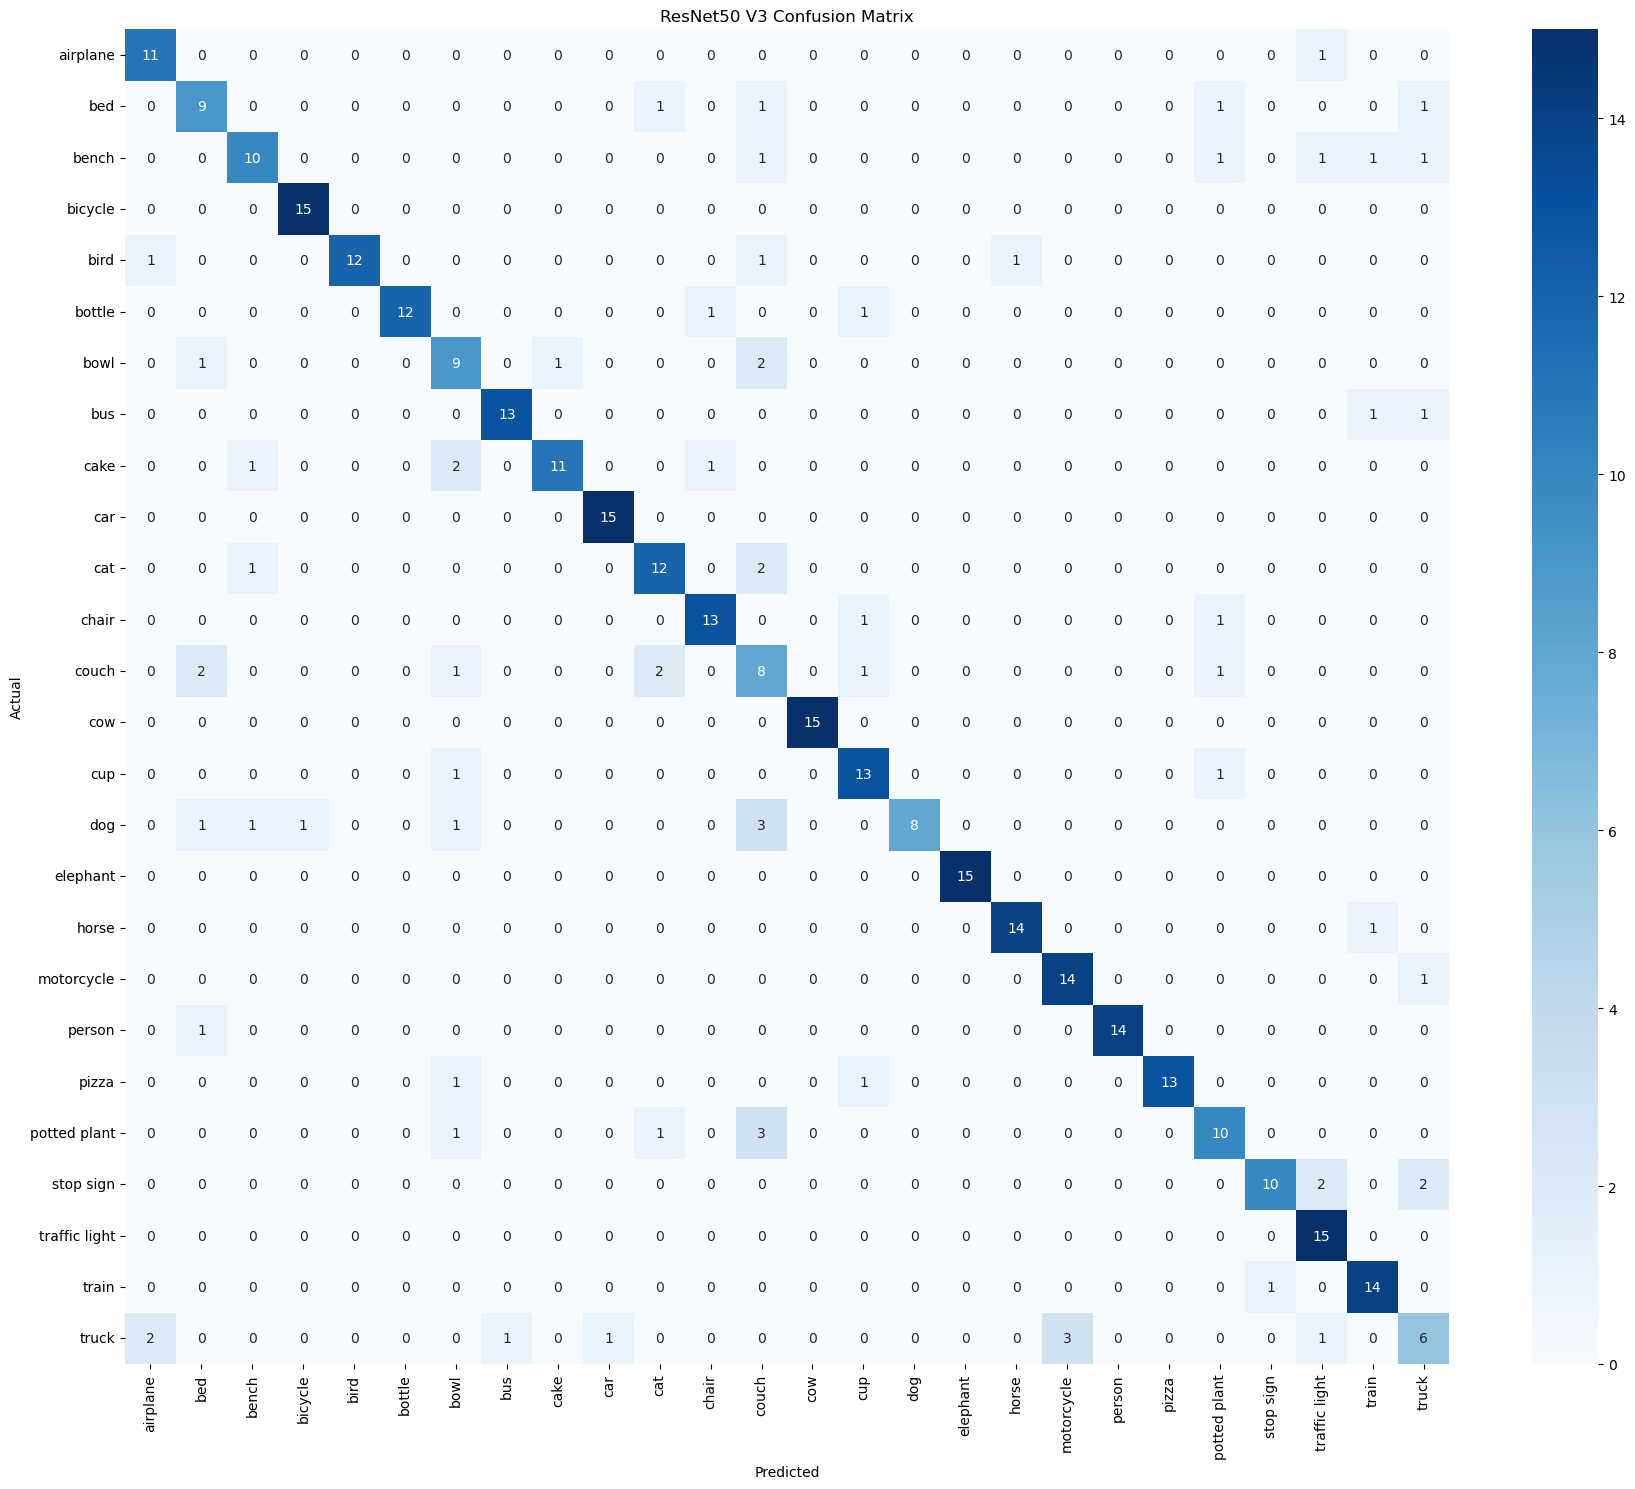

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 V3 Confusion Matrix")

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

weak_classes = ["truck", "couch", "bowl", "dog", "bed"]

mistakes = []

for true_label, pred_label in zip(all_labels, all_preds):
    true_class = class_names[true_label]
    pred_class = class_names[pred_label]

    if true_class in weak_classes and true_class != pred_class:
        mistakes.append({
            "true_class": true_class,
            "predicted_class": pred_class
        })

mistakes_df = pd.DataFrame(mistakes)

print(mistakes_df)
print()
print(mistakes_df.groupby(["true_class", "predicted_class"]).size())

   true_class predicted_class
0         bed           truck
1         bed           couch
2         bed    potted plant
3         bed             cat
4        bowl            cake
5        bowl           couch
6        bowl             bed
7        bowl           couch
8       couch             cup
9       couch             cat
10      couch    potted plant
11      couch            bowl
12      couch             bed
13      couch             cat
14      couch             bed
15        dog           bench
16        dog           couch
17        dog            bowl
18        dog         bicycle
19        dog           couch
20        dog             bed
21        dog           couch
22      truck        airplane
23      truck   traffic light
24      truck      motorcycle
25      truck        airplane
26      truck             car
27      truck             bus
28      truck      motorcycle
29      truck      motorcycle

true_class  predicted_class
bed         cat                1
        

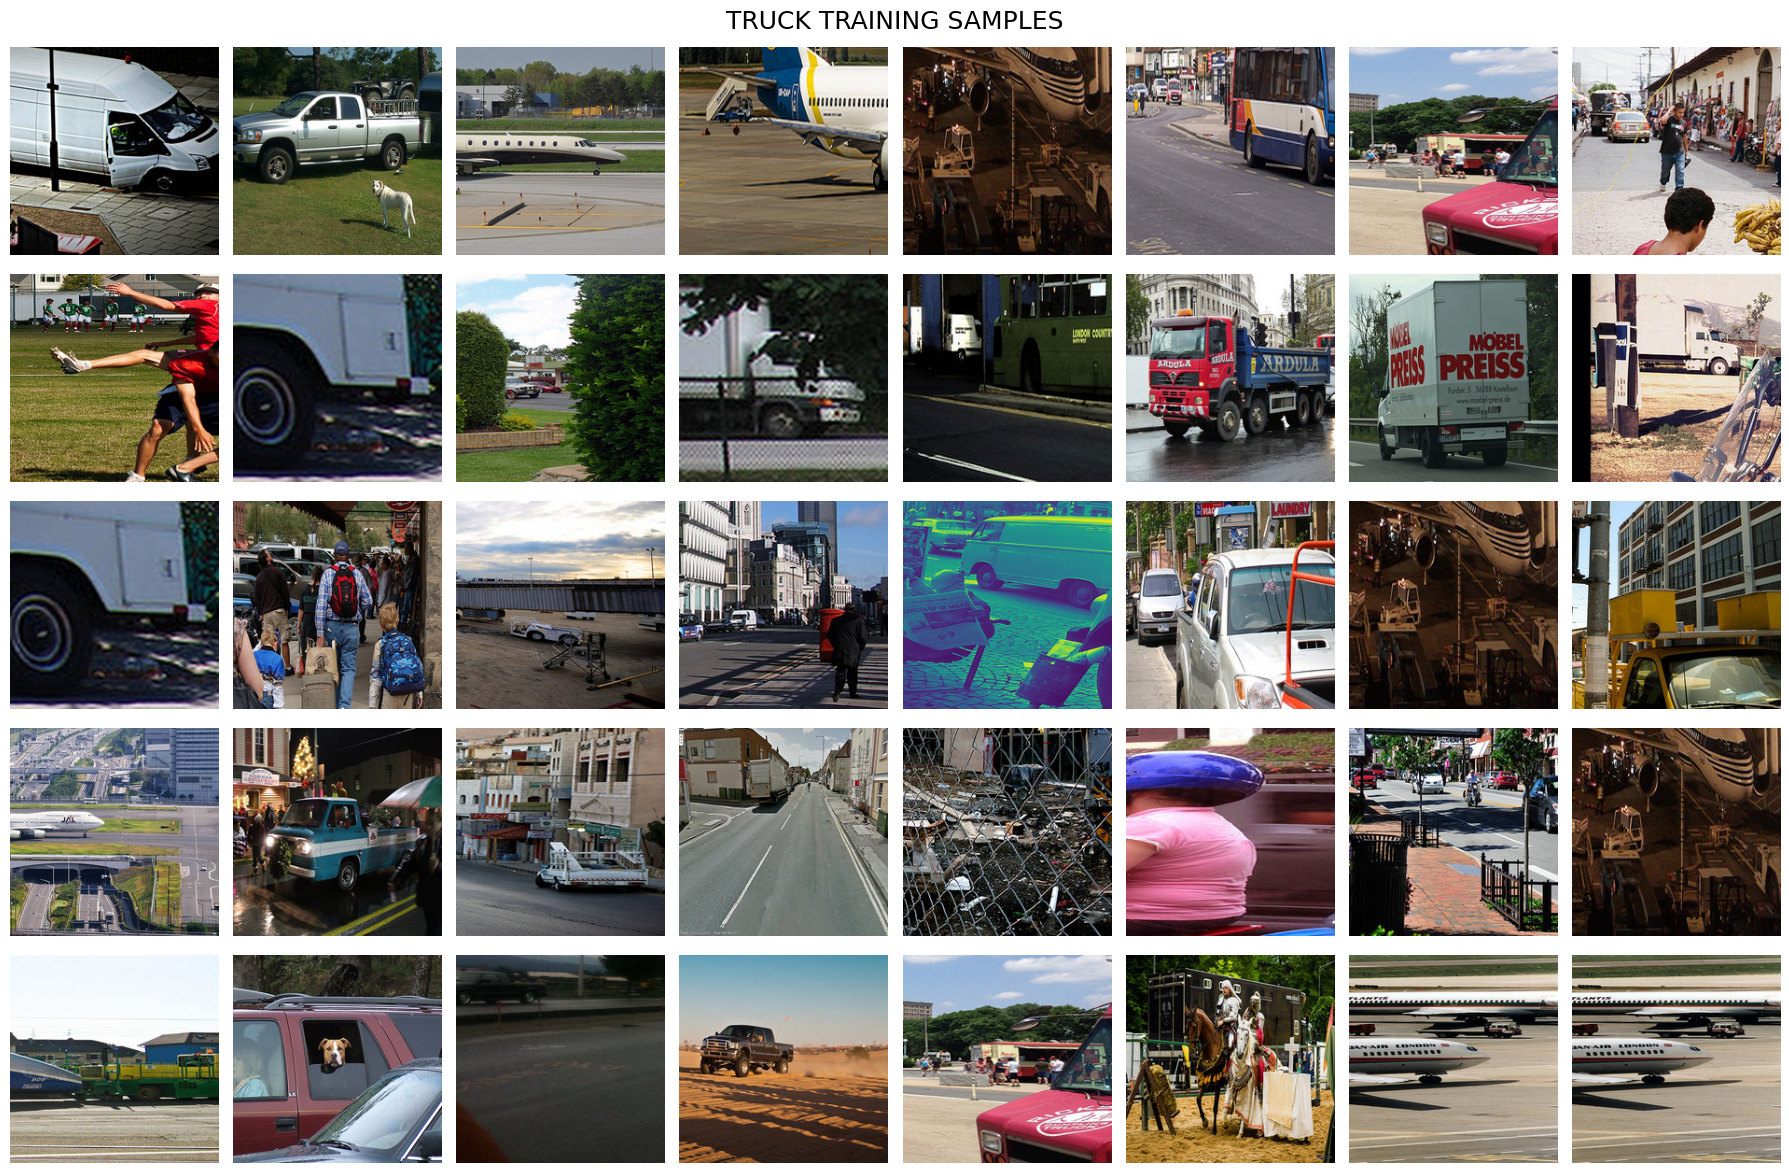

In [18]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

folder = r"E:\SmartVision-AI\data\classification_v3\train\truck"

files = random.sample(
    os.listdir(folder),
    min(40, len(os.listdir(folder)))
)

fig, axes = plt.subplots(5, 8, figsize=(18, 12))
axes = axes.flatten()

for ax, file in zip(axes, files):

    img = Image.open(
        os.path.join(folder, file)
    )

    ax.imshow(img)
    ax.axis("off")

plt.suptitle("TRUCK TRAINING SAMPLES", fontsize=18)
plt.tight_layout()
plt.show()

In [19]:
import os

truck_folder = r"E:\SmartVision-AI\data\classification_v3\train\truck"

print("Truck train images:", len(os.listdir(truck_folder)))

Truck train images: 68


In [20]:
import shutil
import os

src = r"E:\SmartVision-AI\data\classification_v3"
dst = r"E:\SmartVision-AI\data\classification_v3_clean"

if not os.path.exists(dst):
    shutil.copytree(src, dst)
    print("✅ Clean copy created")
else:
    print("⚠️ classification_v3_clean already exists")

✅ Clean copy created


In [21]:
import os

folder = r"E:\SmartVision-AI\data\classification_v3_clean\train\truck"
print("Remaining truck images:", len(os.listdir(folder)))

Remaining truck images: 68


In [22]:
import os

folder = r"E:\SmartVision-AI\data\classification_v3_clean\train\truck"
print("Remaining truck images:", len(os.listdir(folder)))

Remaining truck images: 68


In [23]:
import os
import shutil
import torch
from PIL import Image

from torchvision import transforms

CHECK_CLASS = "truck"

folder = r"E:\SmartVision-AI\data\classification_v3_clean\train\truck"
bad_folder = r"E:\SmartVision-AI\data\classification_v3_clean_removed\truck"

os.makedirs(bad_folder, exist_ok=True)

model.eval()

bad_files = []

for file in os.listdir(folder):
    img_path = os.path.join(folder, file)

    img = Image.open(img_path).convert("RGB")
    img_tensor = val_test_transforms(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.softmax(output, dim=1)
        conf, pred_idx = torch.max(probs, 1)

    pred_class = class_names[pred_idx.item()]
    confidence = conf.item()

    if pred_class != CHECK_CLASS and confidence >= 0.70:
        bad_files.append((file, pred_class, confidence))

print("Suspicious files found:", len(bad_files))

for file, pred_class, confidence in bad_files:
    print(file, "->", pred_class, round(confidence, 3))

Suspicious files found: 1
truck_train_0069.jpg -> traffic light 0.957


In [24]:
CHECK_CLASS = "truck"

folder = r"E:\SmartVision-AI\data\classification_v3_clean\train\truck"

model.eval()

suspicious_files = []

for file in os.listdir(folder):
    img_path = os.path.join(folder, file)

    img = Image.open(img_path).convert("RGB")
    img_tensor = val_test_transforms(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.softmax(output, dim=1)
        conf, pred_idx = torch.max(probs, 1)

    pred_class = class_names[pred_idx.item()]
    confidence = conf.item()

    if pred_class != CHECK_CLASS:
        suspicious_files.append((file, pred_class, confidence))

suspicious_files = sorted(
    suspicious_files,
    key=lambda x: x[2],
    reverse=True
)

print("Total suspicious truck files:", len(suspicious_files))
print()

for file, pred_class, confidence in suspicious_files[:20]:
    print(file, "->", pred_class, round(confidence, 3))

Total suspicious truck files: 2

truck_train_0069.jpg -> traffic light 0.957
truck_train_0047.jpg -> bus 0.56


In [25]:
from collections import Counter
import torch

labels = [label for _, label in train_dataset.samples]
class_counts = Counter(labels)

weights = []
for i in range(num_classes):
    weights.append(1.0 / class_counts[i])

class_weights = torch.tensor(weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

In [26]:
from collections import Counter
import torch

labels = [label for _, label in train_dataset.samples]
class_counts = Counter(labels)

weights = []

for i in range(num_classes):
    weights.append(1.0 / class_counts[i])

class_weights = torch.tensor(weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Class weights created")

Class weights created


In [27]:
model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(num_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, num_classes)
)

model = model.to(device)

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print(model.fc)

Sequential(
  (0): Linear(in_features=2048, out_features=512, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=512, out_features=26, bias=True)
)


In [28]:
history_weighted = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)


Epoch 1/10
------------------------------
Train Loss: 2.2058 | Train Acc: 0.4231
Val Loss:   1.3794 | Val Acc:   0.6162
✅ Best model saved

Epoch 2/10
------------------------------
Train Loss: 1.1425 | Train Acc: 0.6777
Val Loss:   1.1712 | Val Acc:   0.6997
✅ Best model saved

Epoch 3/10
------------------------------
Train Loss: 0.8456 | Train Acc: 0.7521
Val Loss:   1.0535 | Val Acc:   0.7206
✅ Best model saved

Epoch 4/10
------------------------------
Train Loss: 0.6193 | Train Acc: 0.8130
Val Loss:   1.0229 | Val Acc:   0.7050

Epoch 5/10
------------------------------
Train Loss: 0.5573 | Train Acc: 0.8344
Val Loss:   0.9367 | Val Acc:   0.7441
✅ Best model saved

Epoch 6/10
------------------------------
Train Loss: 0.4331 | Train Acc: 0.8755
Val Loss:   0.9816 | Val Acc:   0.7546
✅ Best model saved

Epoch 7/10
------------------------------
Train Loss: 0.3720 | Train Acc: 0.8873
Val Loss:   0.9564 | Val Acc:   0.7389

Epoch 8/10
------------------------------
Train Loss: 0.3

In [6]:
model.load_state_dict(
    torch.load(
        r"E:\SmartVision-AI\models\resnet50_v3_8184.pth"
    )
)

model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [7]:
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("ResNet50 Test Accuracy:", round(test_acc, 4))
print()
print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names
))

ResNet50 Test Accuracy: 0.8184

               precision    recall  f1-score   support

     airplane       0.79      0.92      0.85        12
          bed       0.64      0.69      0.67        13
        bench       0.77      0.67      0.71        15
      bicycle       0.94      1.00      0.97        15
         bird       1.00      0.80      0.89        15
       bottle       1.00      0.86      0.92        14
         bowl       0.56      0.69      0.62        13
          bus       0.93      0.87      0.90        15
         cake       0.92      0.73      0.81        15
          car       0.94      1.00      0.97        15
          cat       0.75      0.80      0.77        15
        chair       0.87      0.87      0.87        15
        couch       0.38      0.53      0.44        15
          cow       1.00      1.00      1.00        15
          cup       0.76      0.87      0.81        15
          dog       1.00      0.53      0.70        15
     elephant       1.00      1.

In [16]:
torch.save(
    model.state_dict(),
    r"E:\SmartVision-AI\models\resnet50_v3_8184.pth"
)

resnet50_v3_8184_results = {
    "model": "ResNet50_classification_v3_extra_finetuned",
    "test_accuracy": 0.8184,
    "precision_macro": 0.83,
    "recall_macro": 0.82,
    "macro_f1": 0.82,
    "weighted_f1": 0.82,
    "num_classes": num_classes
}

with open(r"E:\SmartVision-AI\models\resnet50_v3_8184_metrics.json", "w") as f:
    json.dump(resnet50_v3_8184_results, f, indent=4)

print("Best ResNet50 model saved")

Best ResNet50 model saved


In [31]:
'''resnet50_results = {
    "model": "ResNet50",
    "test_accuracy": 0.7846,
    "precision_macro": 0.80,
    "recall_macro": 0.78,
    "macro_f1": 0.79,
    "num_classes": num_classes
}

with open(r"E:\SmartVision-AI\models\resnet50_metrics.json", "w") as f:
    json.dump(resnet50_results, f, indent=4)

print("ResNet50 metrics saved")'''

ResNet50 metrics saved


In [32]:
# EfficientNet_B0
model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# Freeze feature extractor
for param in model.features.parameters():
    param.requires_grad = False

num_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_features, num_classes)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=26, bias=True)
)


In [33]:
start_time = time.time()

history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

end_time = time.time()
training_time = end_time - start_time

print(f"Training Time: {training_time/60:.2f} minutes")


Epoch 1/10
------------------------------
Train Loss: 2.8984 | Train Acc: 0.2599
Val Loss:   2.5242 | Val Acc:   0.4590
✅ Best model saved

Epoch 2/10
------------------------------
Train Loss: 2.2190 | Train Acc: 0.5203
Val Loss:   2.0898 | Val Acc:   0.5231
✅ Best model saved

Epoch 3/10
------------------------------
Train Loss: 1.8636 | Train Acc: 0.5753
Val Loss:   1.8496 | Val Acc:   0.5538
✅ Best model saved

Epoch 4/10
------------------------------
Train Loss: 1.6383 | Train Acc: 0.6313
Val Loss:   1.7235 | Val Acc:   0.5821
✅ Best model saved

Epoch 5/10
------------------------------
Train Loss: 1.4894 | Train Acc: 0.6401
Val Loss:   1.6163 | Val Acc:   0.5949
✅ Best model saved

Epoch 6/10
------------------------------
Train Loss: 1.3892 | Train Acc: 0.6681
Val Loss:   1.5342 | Val Acc:   0.5897

Epoch 7/10
------------------------------
Train Loss: 1.3176 | Train Acc: 0.6747
Val Loss:   1.4717 | Val Acc:   0.6026
✅ Best model saved

Epoch 8/10
---------------------------

In [34]:
for param in model.features[-3:].parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

history_finetune = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=5
)


Epoch 1/5
------------------------------
Train Loss: 1.0339 | Train Acc: 0.7088
Val Loss:   1.2521 | Val Acc:   0.6564
✅ Best model saved

Epoch 2/5
------------------------------
Train Loss: 0.8313 | Train Acc: 0.7703
Val Loss:   1.1632 | Val Acc:   0.6744
✅ Best model saved

Epoch 3/5
------------------------------
Train Loss: 0.7205 | Train Acc: 0.8126
Val Loss:   1.1398 | Val Acc:   0.6846
✅ Best model saved

Epoch 4/5
------------------------------
Train Loss: 0.6498 | Train Acc: 0.8187
Val Loss:   1.0567 | Val Acc:   0.7231
✅ Best model saved

Epoch 5/5
------------------------------
Train Loss: 0.5562 | Train Acc: 0.8544
Val Loss:   1.0504 | Val Acc:   0.7051


In [35]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("EfficientNetB0 Test Accuracy:", round(test_acc, 4))
print()
print(classification_report(all_labels, all_preds, target_names=class_names))

EfficientNetB0 Test Accuracy: 0.7256

               precision    recall  f1-score   support

     airplane       0.93      0.93      0.93        15
          bed       1.00      0.47      0.64        15
        bench       0.50      0.60      0.55        15
      bicycle       0.76      0.87      0.81        15
         bird       0.74      0.93      0.82        15
       bottle       0.79      0.73      0.76        15
         bowl       0.47      0.60      0.53        15
          bus       0.80      0.80      0.80        15
         cake       1.00      0.73      0.85        15
          car       0.52      1.00      0.68        15
          cat       0.71      0.80      0.75        15
        chair       0.62      0.67      0.65        15
        couch       0.60      0.60      0.60        15
          cow       1.00      0.93      0.97        15
          cup       0.61      0.73      0.67        15
          dog       0.64      0.60      0.62        15
     elephant       1.00  

In [36]:
efficientnet_results = {
    "model": "EfficientNetB0",
    "test_accuracy": 0.7256,
    "precision_macro": 0.75,
    "recall_macro": 0.73,
    "macro_f1": 0.72,
    "num_classes": num_classes
}

with open(r"E:\SmartVision-AI\models\efficientnetb0_metrics.json", "w") as f:
    json.dump(efficientnet_results, f, indent=4)

torch.save(model.state_dict(), r"E:\SmartVision-AI\models\efficientnetb0_best.pth")

print("EfficientNetB0 metrics and model saved")

EfficientNetB0 metrics and model saved


In [38]:
# VGG16

model = models.vgg16(
    weights=models.VGG16_Weights.DEFAULT
)

# Freeze convolutional base
for param in model.features.parameters():
    param.requires_grad = False

num_features = model.classifier[6].in_features

model.classifier[6] = nn.Linear(num_features, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\athiy/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|███████████████████████████████████████████████████████████████████████████████| 528M/528M [03:07<00:00, 2.96MB/s]


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=26, bias=True)
)


In [39]:
start_time = time.time()

history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

end_time = time.time()
training_time = end_time - start_time

print(f"Training Time: {training_time/60:.2f} minutes")


Epoch 1/10
------------------------------
Train Loss: 2.6642 | Train Acc: 0.2670
Val Loss:   1.8678 | Val Acc:   0.4744
✅ Best model saved

Epoch 2/10
------------------------------
Train Loss: 1.7056 | Train Acc: 0.5176
Val Loss:   1.5312 | Val Acc:   0.5692
✅ Best model saved

Epoch 3/10
------------------------------
Train Loss: 1.4922 | Train Acc: 0.6066
Val Loss:   1.4916 | Val Acc:   0.6077
✅ Best model saved

Epoch 4/10
------------------------------
Train Loss: 1.4005 | Train Acc: 0.6505
Val Loss:   1.3860 | Val Acc:   0.6744
✅ Best model saved

Epoch 5/10
------------------------------
Train Loss: 1.2750 | Train Acc: 0.6973
Val Loss:   1.5669 | Val Acc:   0.6718

Epoch 6/10
------------------------------
Train Loss: 1.3285 | Train Acc: 0.7099
Val Loss:   1.7979 | Val Acc:   0.6769
✅ Best model saved

Epoch 7/10
------------------------------
Train Loss: 1.2734 | Train Acc: 0.7203
Val Loss:   1.6889 | Val Acc:   0.6513

Epoch 8/10
------------------------------
Train Loss: 1.2

In [40]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)

print("VGG16 Test Accuracy:", round(test_acc, 4))
print()
print(classification_report(all_labels, all_preds, target_names=class_names))

VGG16 Test Accuracy: 0.6615

               precision    recall  f1-score   support

     airplane       1.00      0.60      0.75        15
          bed       0.75      0.20      0.32        15
        bench       0.22      0.60      0.32        15
      bicycle       0.80      0.53      0.64        15
         bird       0.74      0.93      0.82        15
       bottle       0.79      0.73      0.76        15
         bowl       0.67      0.27      0.38        15
          bus       0.92      0.80      0.86        15
         cake       0.75      0.60      0.67        15
          car       0.78      0.93      0.85        15
          cat       1.00      0.60      0.75        15
        chair       0.79      0.73      0.76        15
        couch       0.44      0.80      0.57        15
          cow       0.82      0.93      0.88        15
          cup       0.41      0.73      0.52        15
          dog       0.56      0.33      0.42        15
     elephant       0.92      0.80 

In [41]:
torch.save(model.state_dict(), r"E:\SmartVision-AI\models\vgg16_best.pth")

In [42]:
torch.save(
    model.state_dict(),
    r"E:\SmartVision-AI\models\vgg16_best.pth"
)

vgg16_results = {
    "model": "VGG16",
    "test_accuracy": 0.6615,
    "precision_macro": 0.73,
    "recall_macro": 0.66,
    "macro_f1": 0.66,
    "num_classes": num_classes
}

with open(r"E:\SmartVision-AI\models\vgg16_metrics.json", "w") as f:
    json.dump(vgg16_results, f, indent=4)

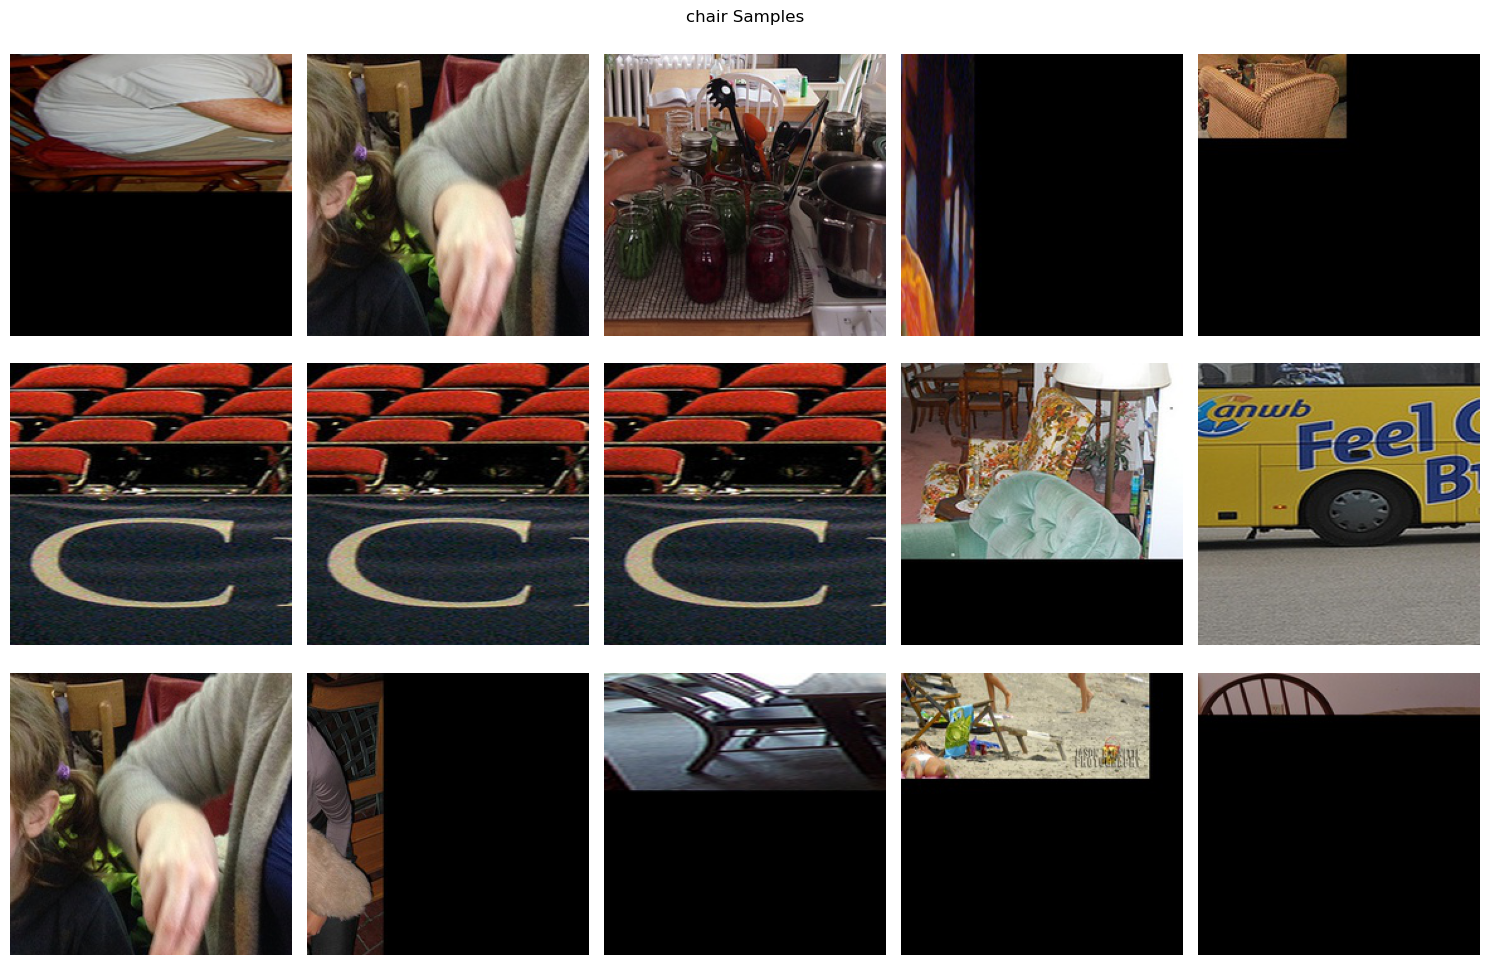

In [43]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

class_name = "chair"   # try bird, bottle, chair

folder = rf"E:\SmartVision-AI\data\classification\test\{class_name}"

files = random.sample(os.listdir(folder), min(15, len(os.listdir(folder))))

fig, axes = plt.subplots(3, 5, figsize=(15, 10))

for ax, file in zip(axes.flatten(), files):
    img = Image.open(os.path.join(folder, file))
    ax.imshow(img)
    ax.axis("off")

plt.suptitle(f"{class_name} Samples")
plt.tight_layout()
plt.show()